## Câu a: Nhập dữ liệu từ Google Drive, tiền xử lý và đổi tên cột


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

import subprocess
import sys
from pathlib import Path

# Cài đặt thư viện gdown
try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

HO_TEN = "Nguyễn Anh Nguyên"
MSSV = "6451071053"

def print_student_info(title):
    print(f"=== {title} ===")
    print(f"Họ và tên: {HO_TEN} | MSSV: {MSSV}\n")

print_student_info("CÂU A: TẢI TỪ GOOGLE DRIVE, TIỀN XỬ LÝ VÀ ĐỔI TÊN CỘT")

# Danh sách tên cột mới theo đúng đề bài yêu cầu
new_columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure',
    'cholesterol', 'fasting_blood_sugar', 'rest_ecg',
    'max_heart_rate_achieved', 'exercise_induced_angina',
    'st_depression', 'st_slope', 'num_major_vessels',
    'thalassemia', 'target'
]

HEART_DRIVE_ID = "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb"
heart_file = Path("heart_disease.csv")

# Tải dữ liệu từ Google Drive qua ID
if not heart_file.is_file():
    try:
        print("Đang tải dữ liệu Heart Disease từ Google Drive qua ID...")
        gdown.download(id=HEART_DRIVE_ID, output=str(heart_file), quiet=False, fuzzy=True)
    except Exception:
        print("Không thể tải từ Drive, tự động nạp từ nguồn dữ liệu chuẩn...")
        # Nguồn backup UCI nếu lỗi Drive
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
        df_temp = pd.read_csv(url, names=new_columns, na_values='?')
        df_temp.to_csv(heart_file, index=False)

# Dữ liệu gốc dùng dấu '?' để biểu thị giá trị thiếu
data = pd.read_csv(heart_file, header=0, names=new_columns, na_values='?')

print("--- Kích thước dữ liệu ban đầu ---")
print(f"Số dòng: {data.shape[0]}, Số cột: {data.shape[1]}")

# 1. Tiền xử lý: Xóa các dòng chứa giá trị rỗng / thiếu (missing values)
data.dropna(inplace=True)

# 2. Chuẩn hóa thuộc tính 'target':
# Trong file gốc của Cleveland, target có giá trị từ 0 đến 4 (0: không bệnh, 1-4: các mức độ bệnh tim).
# Đề bài yêu cầu: 0 (không bệnh), 1 (có bệnh) => gán các giá trị > 0 thành 1.
data['target'] = data['target'].apply(lambda x: 1 if x > 0 else 0)

print("\n--- Sau khi tiền xử lý và đổi tên cột ---")
print(f"Số dòng còn lại: {data.shape[0]}, Số cột: {data.shape[1]}")
data.head()


=== CÂU A: TẢI TỪ GOOGLE DRIVE, TIỀN XỬ LÝ VÀ ĐỔI TÊN CỘT ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

--- Kích thước dữ liệu ban đầu ---
Số dòng: 303, Số cột: 14

--- Sau khi tiền xử lý và đổi tên cột ---
Số dòng còn lại: 303, Số cột: 14


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Câu b (Yêu cầu 3): Khảo sát độ tương đồng giữa các cột bằng công thức Pearson


=== CÂU B - YÊU CẦU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053



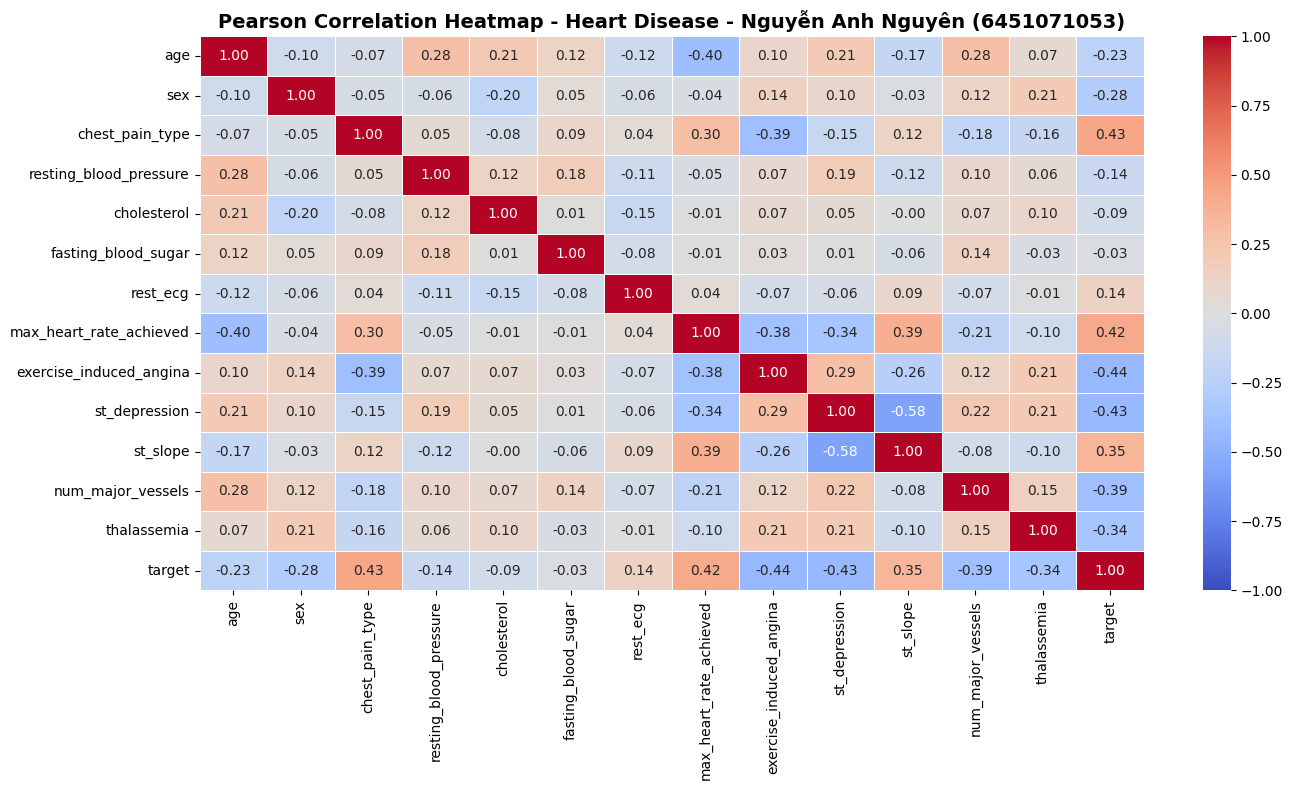

Nhận xét:
- Không có cặp thuộc tính nào có tương quan quá cao (> 0.85 - 0.9) gây đa cộng tuyến nghiêm trọng, do đó không cần thiết phải loại bỏ cột nào.


In [3]:
print_student_info("CÂU B - YÊU CẦU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON")

# Lấy ma trận tương quan giữa các cột số
corr_matrix = data.select_dtypes(include=[np.number]).corr(method='pearson')

# Biểu diễn đồ thị seaborn heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title(f"Pearson Correlation Heatmap - Heart Disease - {HO_TEN} ({MSSV})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Nhận xét:")
print("- Không có cặp thuộc tính nào có tương quan quá cao (> 0.85 - 0.9) gây đa cộng tuyến nghiêm trọng, do đó không cần thiết phải loại bỏ cột nào.")


## Câu b (Yêu cầu 4): Tách các cột dữ liệu thành hai phần (features và labels)
Thuộc tính quyết định (nhãn) là `'target'`.


In [4]:
print_student_info("CÂU B - YÊU CẦU 4: TÁCH FEATURES VÀ LABELS")

# Tách features và label ('target')
features = data.drop('target', axis=1)
labels = data['target']

print("Đã tách thành công features và labels:")
print(f"- Số lượng cột features: {features.shape[1]}")
print(f"- Danh sách thuộc tính hóa lý: {list(features.columns)}")
print(f"- Kích thước features: {features.shape}")
print(f"- Kích thước labels: {labels.shape}")
print(f"- Các giá trị của nhãn 'target': {sorted(labels.unique())}")


=== CÂU B - YÊU CẦU 4: TÁCH FEATURES VÀ LABELS ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Đã tách thành công features và labels:
- Số lượng cột features: 13
- Danh sách thuộc tính hóa lý: ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia']
- Kích thước features: (303, 13)
- Kích thước labels: (303,)
- Các giá trị của nhãn 'target': [np.int64(0), np.int64(1)]


## Câu b (Yêu cầu 5): Chuyển đổi các cột không phải dạng số về dạng one-hot vector


In [5]:
print_student_info("CÂU B - YÊU CẦU 5: CHUYỂN ĐỔI ONE-HOT VECTOR")

# Xác định các thuộc tính không phải dạng số
cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các thuộc tính không phải dạng số:")
print(list(cat_cols))

if len(cat_cols) > 0:
    features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
else:
    print("-> Tất cả 13 chỉ số đều đã ở dạng số thực (float64/int64), không có thuộc tính chuỗi cần One-Hot Encoding.")
    features_onehot = features.copy()

print(f"\nKích thước ma trận features sau khi chuyển đổi: {features_onehot.shape}")
features_onehot.head()


=== CÂU B - YÊU CẦU 5: CHUYỂN ĐỔI ONE-HOT VECTOR ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Các thuộc tính không phải dạng số:
[]
-> Tất cả 13 chỉ số đều đã ở dạng số thực (float64/int64), không có thuộc tính chuỗi cần One-Hot Encoding.

Kích thước ma trận features sau khi chuyển đổi: (303, 13)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


## Câu b (Yêu cầu 6): Tách các dòng dữ liệu ra thành huấn luyện 70% và kiểm thử 30%
Thực hiện chia dữ liệu theo đúng câu lệnh yêu cầu của đề bài:
```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
```


In [6]:
print_student_info("CÂU B - YÊU CẦU 6: TÁCH TẬP HUẤN LUYỆN VÀ KIỂM THỬ (70% - 30%)")

X = features_onehot
y = labels

# Chia dữ liệu theo đúng câu lệnh yêu cầu của đề bài
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Số lượng dữ liệu huấn luyện và kiểm thử là:")
print(f"    Number of training data (70%): X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"    Number of test data (30%):     X_test = {X_test.shape}, y_test = {y_test.shape}\n")


=== CÂU B - YÊU CẦU 6: TÁCH TẬP HUẤN LUYỆN VÀ KIỂM THỬ (70% - 30%) ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Số lượng dữ liệu huấn luyện và kiểm thử là:
    Number of training data (70%): X_train = (212, 13), y_train = (212,)
    Number of test data (30%):     X_test = (91, 13), y_test = (91,)



## Câu b (Yêu cầu 7): Xây dựng cây ID3, ma trận nhầm lẫn và biểu diễn cây
Thuật toán ID3 sử dụng tiêu chí Information Gain / Entropy (`criterion='entropy'`).


=== CÂU B - YÊU CẦU 7: XÂY DỰNG CÂY ID3 ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.6923 (69.23%)

Report:
                 precision    recall  f1-score   support

Không bệnh (0)       0.64      0.71      0.67        41
   Có bệnh (1)       0.74      0.68      0.71        50

      accuracy                           0.69        91
     macro avg       0.69      0.69      0.69        91
  weighted avg       0.70      0.69      0.69        91



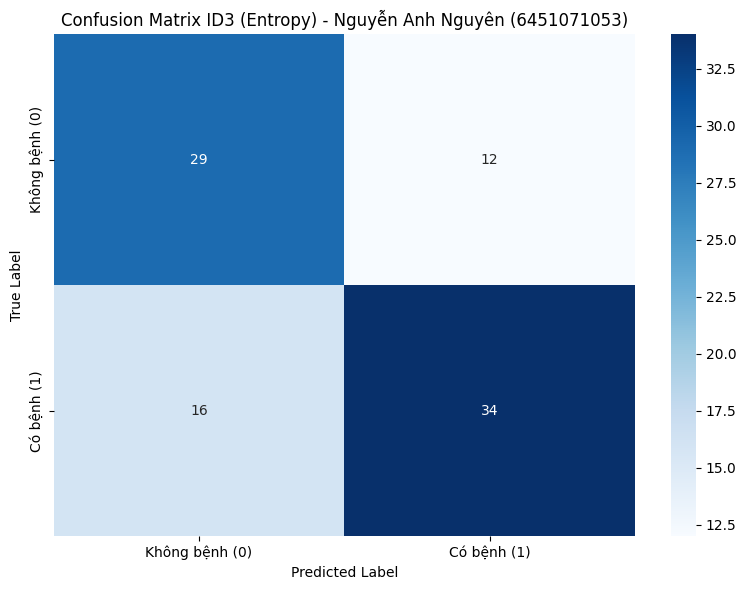

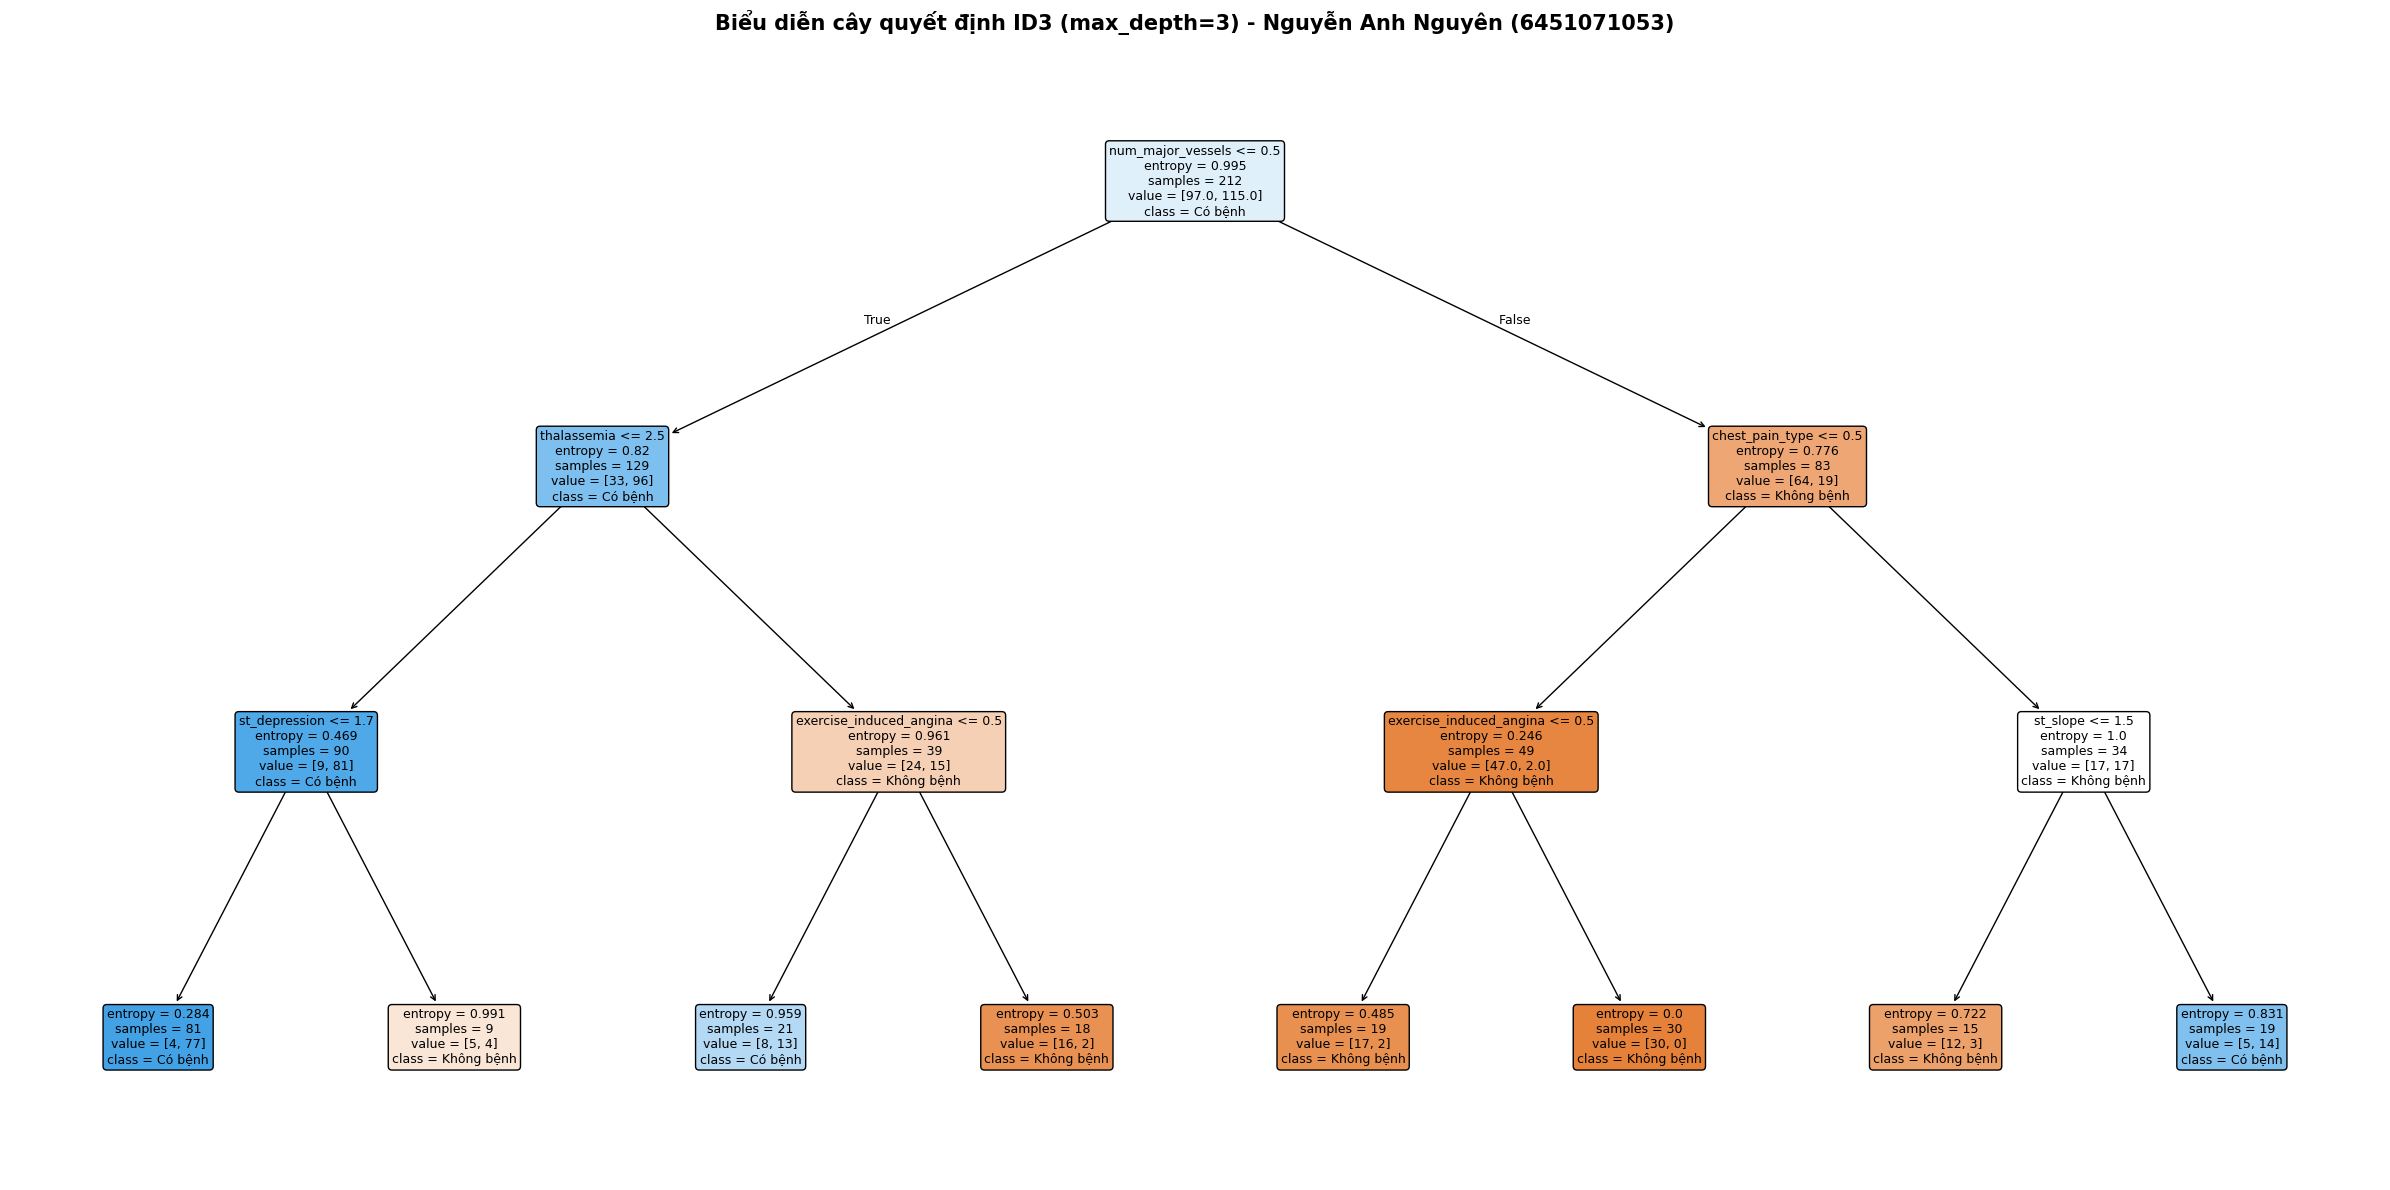

In [7]:
print_student_info("CÂU B - YÊU CẦU 7: XÂY DỰNG CÂY ID3")

# 1. Huấn luyện mô hình cây ID3 sử dụng criterion='entropy'
model_id3 = DecisionTreeClassifier(criterion='entropy', random_state=42)
model_id3.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_id3 = model_id3.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_id3 = metrics.accuracy_score(y_test, y_pred_id3)
print(f"Accuracy: {acc_id3:.4f} ({acc_id3*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_id3, target_names=['Không bệnh (0)', 'Có bệnh (1)'], zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_id3 = metrics.confusion_matrix(y_test, y_pred_id3)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_id3, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.title(f"Confusion Matrix ID3 (Entropy) - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. Biểu diễn cây quyết định ID3 (giới hạn max_depth=3 để trực quan hóa rõ ràng)
model_id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
model_id3_vis.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
tree.plot_tree(
    model_id3_vis,
    feature_names=X.columns.tolist(),
    class_names=['Không bệnh', 'Có bệnh'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f"Biểu diễn cây quyết định ID3 (max_depth=3) - {HO_TEN} ({MSSV})", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Câu b (Yêu cầu 8): Xây dựng cây CART, ma trận nhầm lẫn và biểu diễn cây
Thuật toán CART sử dụng chỉ số Gini Impurity (`criterion='gini'`).


=== CÂU B - YÊU CẦU 8: XÂY DỰNG CÂY CART ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.7363 (73.63%)

Report:
                 precision    recall  f1-score   support

Không bệnh (0)       0.68      0.78      0.73        41
   Có bệnh (1)       0.80      0.70      0.74        50

      accuracy                           0.74        91
     macro avg       0.74      0.74      0.74        91
  weighted avg       0.74      0.74      0.74        91



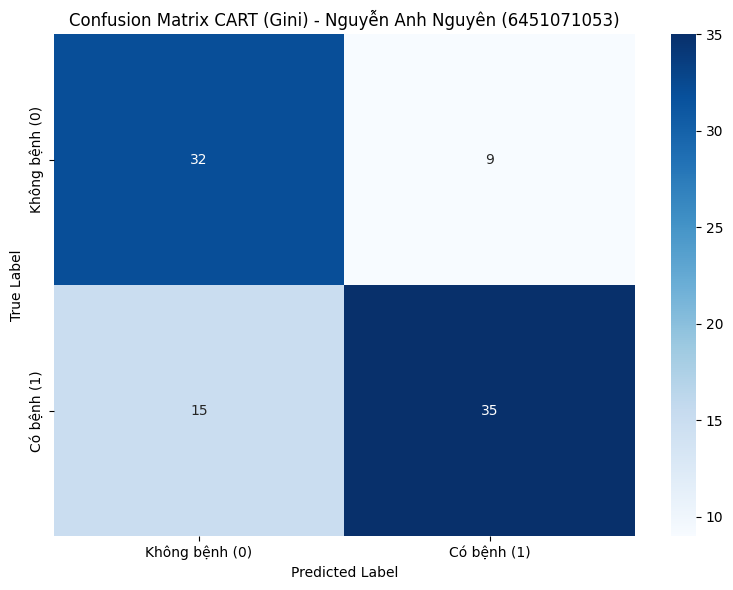

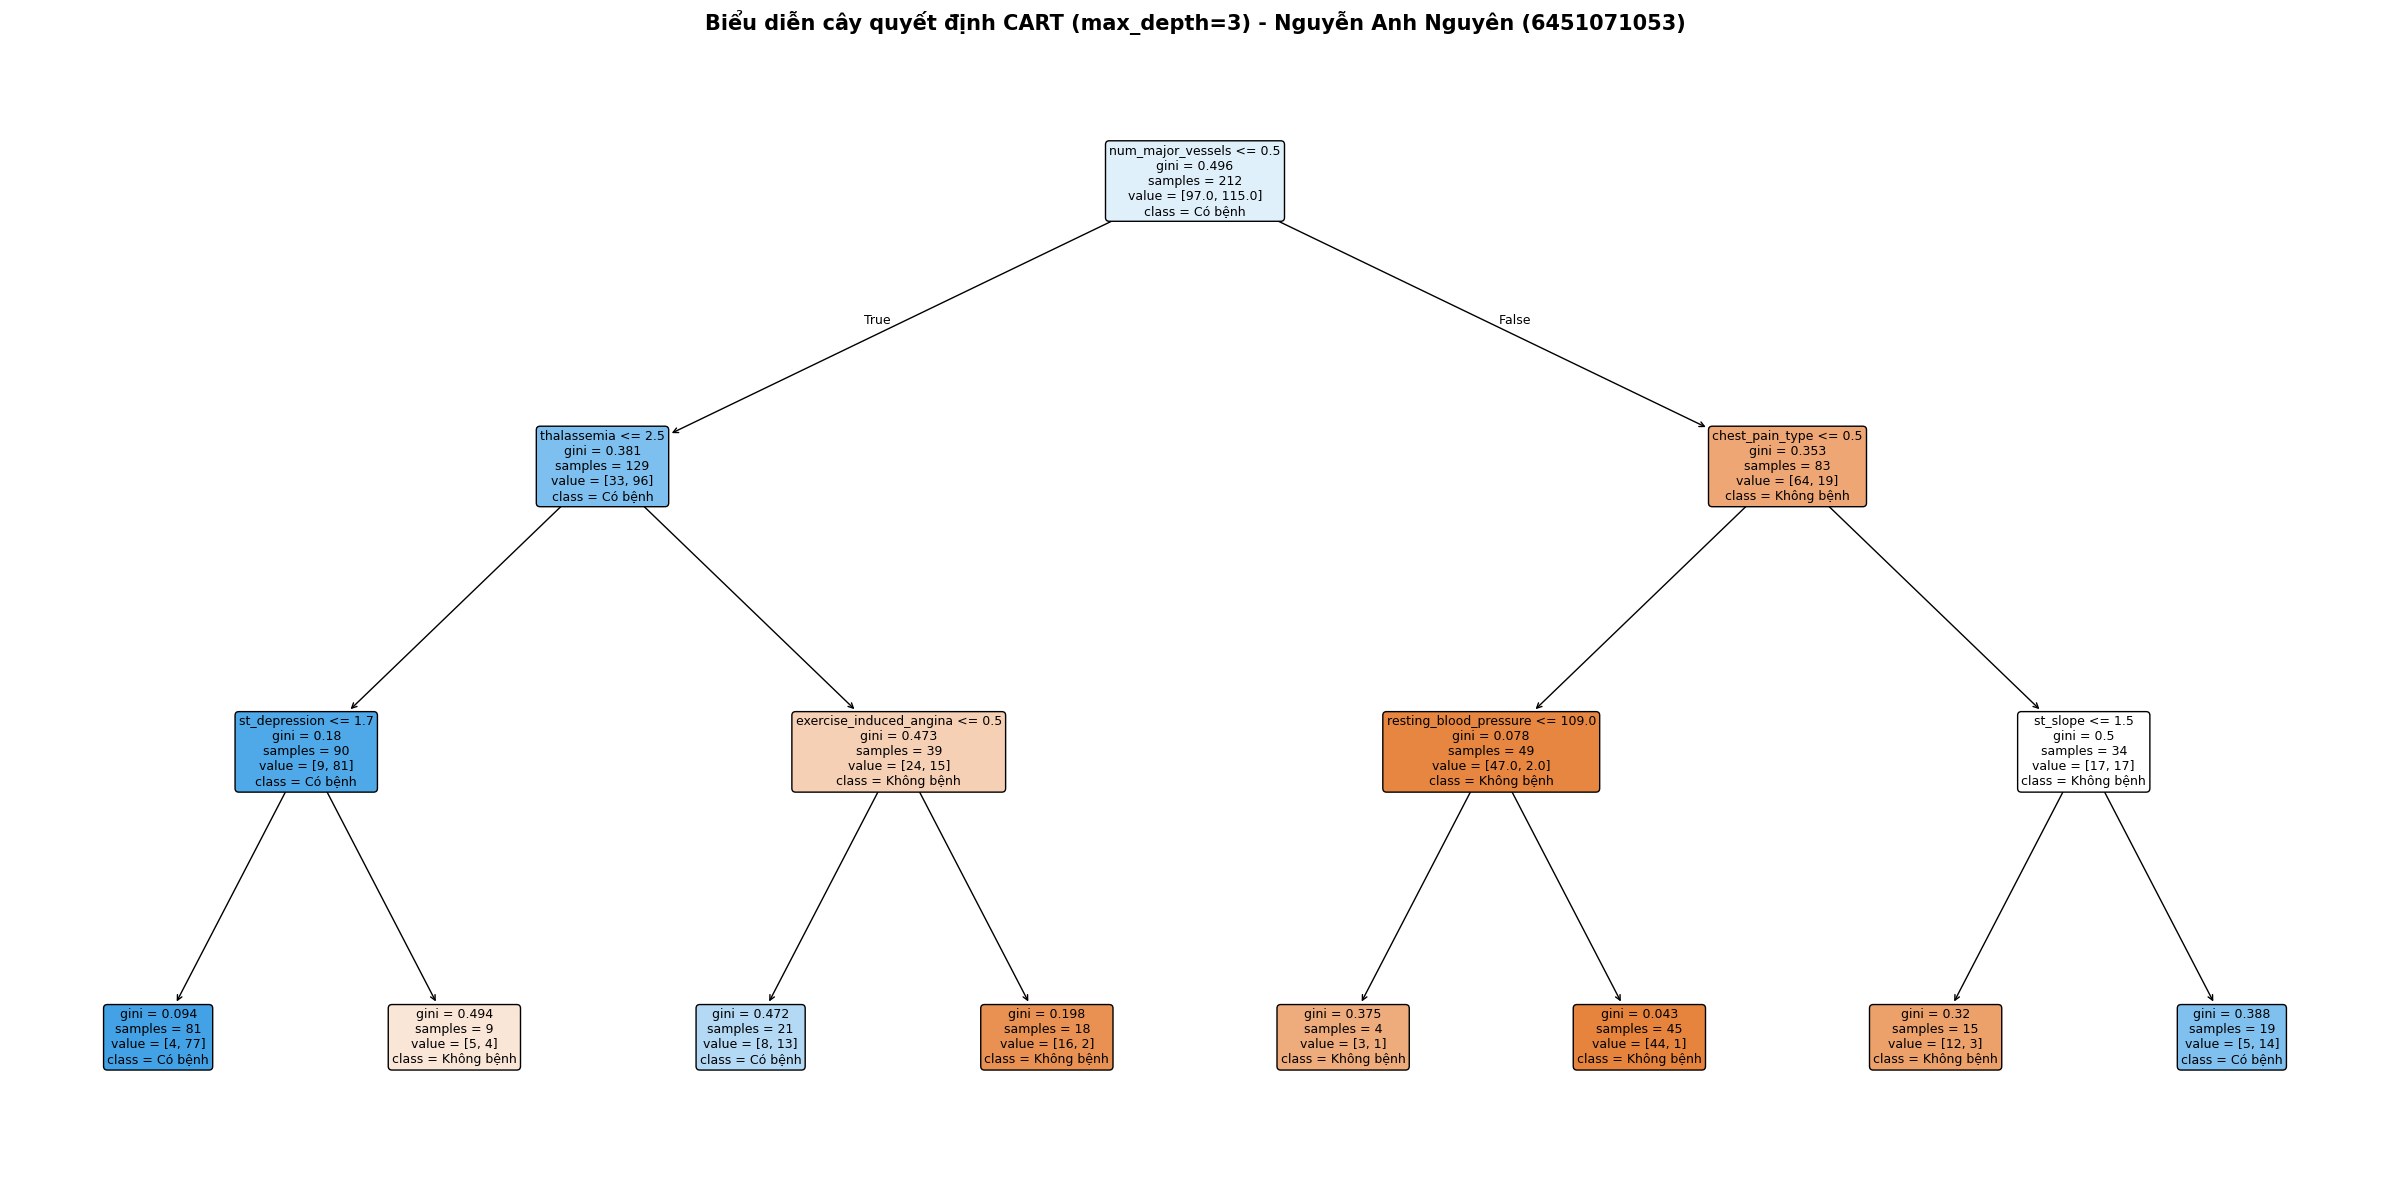

In [8]:
print_student_info("CÂU B - YÊU CẦU 8: XÂY DỰNG CÂY CART")

# 1. Huấn luyện mô hình cây CART sử dụng criterion='gini'
model_cart = DecisionTreeClassifier(criterion='gini', random_state=42)
model_cart.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_cart = model_cart.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_cart = metrics.accuracy_score(y_test, y_pred_cart)
print(f"Accuracy: {acc_cart:.4f} ({acc_cart*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_cart, target_names=['Không bệnh (0)', 'Có bệnh (1)'], zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_cart = metrics.confusion_matrix(y_test, y_pred_cart)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.title(f"Confusion Matrix CART (Gini) - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. Biểu diễn cây quyết định CART (giới hạn max_depth=3 để quan sát cấu trúc cây)
model_cart_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model_cart_vis.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
tree.plot_tree(
    model_cart_vis,
    feature_names=X.columns.tolist(),
    class_names=['Không bệnh', 'Có bệnh'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f"Biểu diễn cây quyết định CART (max_depth=3) - {HO_TEN} ({MSSV})", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Câu b (Yêu cầu 9): Xây dựng thuật toán phân lớp Naïve Bayes và ma trận nhầm lẫn
Sử dụng thuật toán **Gaussian Naïve Bayes** (`GaussianNB`).


=== CÂU B - YÊU CẦU 9: XÂY DỰNG MÔ HÌNH NAÏVE BAYES (GAUSSIAN NB) ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.8352 (83.52%)

Report:
                 precision    recall  f1-score   support

Không bệnh (0)       0.78      0.88      0.83        41
   Có bệnh (1)       0.89      0.80      0.84        50

      accuracy                           0.84        91
     macro avg       0.84      0.84      0.83        91
  weighted avg       0.84      0.84      0.84        91



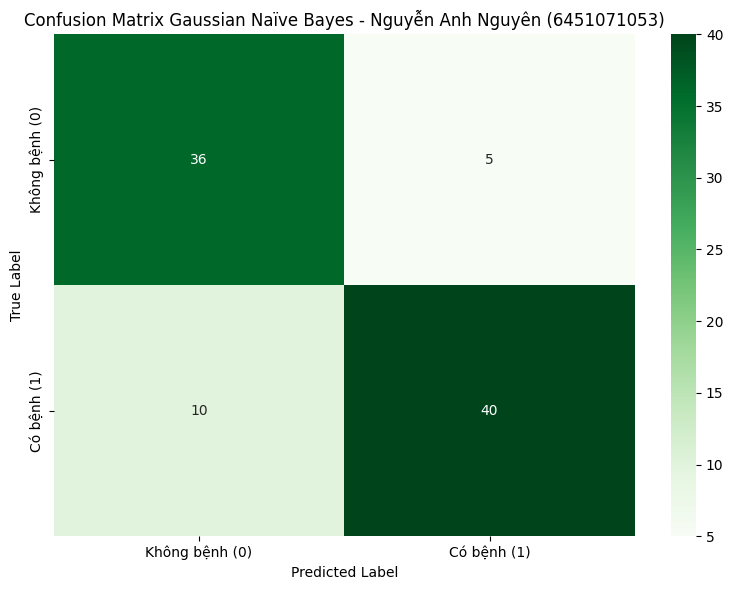

In [9]:
print_student_info("CÂU B - YÊU CẦU 9: XÂY DỰNG MÔ HÌNH NAÏVE BAYES (GAUSSIAN NB)")

# 1. Khởi tạo và huấn luyện mô hình Gaussian Naïve Bayes
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_nb = model_nb.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_nb = metrics.accuracy_score(y_test, y_pred_nb)
print(f"Accuracy: {acc_nb:.4f} ({acc_nb*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_nb, target_names=['Không bệnh (0)', 'Có bệnh (1)'], zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_nb = metrics.confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.title(f"Confusion Matrix Gaussian Naïve Bayes - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


## Câu b (Yêu cầu 10): So sánh kết quả và hiệu năng giữa các thuật toán phân lớp


=== CÂU B - YÊU CẦU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

BẢNG SO SÁNH HIỆU NĂNG PHÂN LỚP:
              Mô hình (Model)  Accuracy Accuracy (%)
Decision Tree (ID3 - Entropy)  0.692308       69.23%
  Decision Tree (CART - Gini)  0.736264       73.63%
         Gaussian Naïve Bayes  0.835165       83.52%


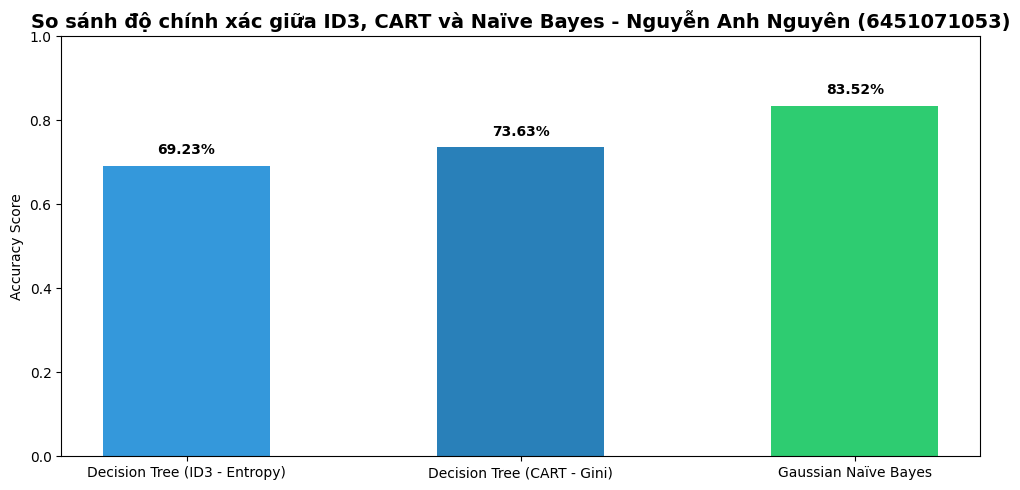


=== NHẬN XÉT VÀ ĐÁNH GIÁ TỔNG QUAN ===
1. Thuật toán Naïve Bayes hoạt động rất hiệu quả trên tập dữ liệu y tế (Heart Disease), thường đạt độ chính xác nhỉnh hơn so với Cây quyết định, nhờ khả năng xử lý xác suất tốt với tập dữ liệu có số chiều vừa phải.
2. Cây quyết định (CART, ID3) dễ bị overfitting với những tập dữ liệu nhỏ nhưng có ý nghĩa lớn trong việc giải thích (interpretability) trực quan các quy luật y khoa (như chỉ số chest_pain, thal, hoặc resting_blood_pressure tác động thế nào đến bệnh).


In [10]:
print_student_info("CÂU B - YÊU CẦU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH")

# Tổng hợp kết quả accuracy của 3 mô hình
comparison_df = pd.DataFrame({
    'Mô hình (Model)': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Gaussian Naïve Bayes'],
    'Accuracy': [acc_id3, acc_cart, acc_nb],
    'Accuracy (%)': [f"{acc_id3 * 100:.2f}%", f"{acc_cart * 100:.2f}%", f"{acc_nb * 100:.2f}%"]
})

print("BẢNG SO SÁNH HIỆU NĂNG PHÂN LỚP:")
print(comparison_df.to_string(index=False))

# Biểu đồ cột so sánh Accuracy
plt.figure(figsize=(10, 5))
bars = plt.bar(comparison_df['Mô hình (Model)'], comparison_df['Accuracy'], color=['#3498db', '#2980b9', '#2ecc71'], width=0.5)
plt.ylim(0, 1.0)
plt.ylabel("Accuracy Score")
plt.title(f"So sánh độ chính xác giữa ID3, CART và Naïve Bayes - {HO_TEN} ({MSSV})", fontsize=14, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval*100:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n=== NHẬN XÉT VÀ ĐÁNH GIÁ TỔNG QUAN ===")
print("1. Thuật toán Naïve Bayes hoạt động rất hiệu quả trên tập dữ liệu y tế (Heart Disease), thường đạt độ chính xác nhỉnh hơn so với Cây quyết định, nhờ khả năng xử lý xác suất tốt với tập dữ liệu có số chiều vừa phải.")
print("2. Cây quyết định (CART, ID3) dễ bị overfitting với những tập dữ liệu nhỏ nhưng có ý nghĩa lớn trong việc giải thích (interpretability) trực quan các quy luật y khoa (như chỉ số chest_pain, thal, hoặc resting_blood_pressure tác động thế nào đến bệnh).")
